# Bab 8: Learning Signal and Ignoring Noise — Introduction to Regularization and Batching

Notebook ini merangkum Bab 8 buku *Grokking Deep Learning* karya Andrew W. Trask. Bab ini membahas musuh bebuyutan neural network, yaitu **overfitting**, dan dua teknik yang dipakai hampir di semua arsitektur: **regularisasi** (terutama early stopping dan dropout) serta **mini-batch gradient descent**.

Isi notebook:

1. Network tiga layer pada MNIST
2. Memorization vs generalization
3. Overfitting pada neural network
4. Dari mana overfitting datang
5. Early stopping
6. Dropout
7. Mengapa dropout berhasil: ensembling
8. Dropout dalam kode dan evaluasinya pada MNIST
9. Batch gradient descent

## 1. Network Tiga Layer pada MNIST

Beberapa bab terakhir memperlihatkan bahwa neural network memodelkan korelasi. Hidden layer bahkan bisa menciptakan korelasi perantara untuk membantu menyelesaikan tugas. Pertanyaannya: bagaimana kita tahu network menciptakan korelasi yang baik?

Di Bab 5 ada eksperimen ketika satu weight dibekukan lalu network dilanjutkan training. Weight yang dibekukan tetap menemukan dasar "mangkuk" errornya, seolah mangkuk itu bergeser agar nilai weight tadi menjadi optimal. Kalau weight dilepas lagi, network tidak belajar apa-apa karena error sudah 0. Bagi network, tidak ada lagi yang perlu dipelajari.

Itu memunculkan pertanyaan: bagaimana kalau input pada weight yang dibekukan itu penting untuk memprediksi kemenangan baseball di dunia nyata? Bagaimana kalau network sudah menemukan cara memprediksi semua pertandingan di data latih (karena itulah yang dilakukan network: meminimalkan error), tetapi melupakan input yang berharga?

Fenomena ini, **overfitting**, sangat umum. Boleh dibilang ini musuh bebuyutan neural network. Semakin besar kekuatan ekspresif network (lebih banyak layer dan weight), semakin mudah ia overfit. Riset terus mencari tugas yang membutuhkan layer lebih kuat, lalu harus memecahkan masalah agar network tidak overfit.

Kita mulai dari network paling kuat yang sudah dipelajari (tiga layer, hidden layer relu) pada tugas paling menantang (klasifikasi digit MNIST). Pertama, muat datanya.

In [1]:
import sys
import numpy as np

np.random.seed(1)

# Memuat MNIST. Buku memakai keras; kalau tidak tersedia, dipakai OpenML lewat scikit-learn.
try:
    from keras.datasets import mnist
    (x_train, y_train), (x_test, y_test) = mnist.load_data()
except Exception:
    from sklearn.datasets import fetch_openml
    mn = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
    X_all, y_all = mn.data.astype("float64"), mn.target.astype(int)
    x_train, y_train = X_all[:60000], y_all[:60000]
    x_test, y_test = X_all[60000:], y_all[60000:]

# 1000 gambar pertama untuk latihan, seluruh data uji untuk evaluasi
images = x_train[0:1000].reshape(1000, 28 * 28) / 255
labels = y_train[0:1000]

one_hot_labels = np.zeros((len(labels), 10))
for i, l in enumerate(labels):
    one_hot_labels[i][l] = 1
labels = one_hot_labels

test_images = x_test.reshape(len(x_test), 28 * 28) / 255
test_labels = np.zeros((len(y_test), 10))
for i, l in enumerate(y_test):
    test_labels[i][l] = 1

print(images.shape, labels.shape, test_images.shape, test_labels.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(1000, 784) (1000, 10) (10000, 784) (10000, 10)


Sekarang training. Network ini punya 784 input piksel, hidden layer 40 neuron dengan `relu`, dan 10 output (satu per digit). Hanya 1000 gambar pertama yang dipakai untuk training.

In [2]:
relu = lambda x: (x >= 0) * x          # x kalau x > 0, selain itu 0
relu2deriv = lambda x: x >= 0          # 1 kalau input > 0, selain itu 0

alpha, iterations, hidden_size, pixels_per_image, num_labels = (0.005, 350, 40, 784, 10)

weights_0_1 = 0.2 * np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

for j in range(iterations):
    error, correct_cnt = (0.0, 0)

    for i in range(len(images)):
        layer_0 = images[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)

        error += np.sum((labels[i:i+1] - layer_2) ** 2)
        correct_cnt += int(np.argmax(layer_2) == np.argmax(labels[i:i+1]))

        layer_2_delta = (labels[i:i+1] - layer_2)
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    sys.stdout.write("\r I:" + str(j) +
                     " Error:" + str(error / float(len(images)))[0:5] +
                     " Correct:" + str(correct_cnt / float(len(images))))

 I:349 Error:0.104 Correct:1.0

## 2. Well, That Was Easy

Network sempurna memprediksi 1000 gambar (di buku, akurasi training akhirnya 100%). Dalam satu hal ini kemenangan nyata: dari 1000 gambar, network belajar mengorelasikan tiap gambar dengan label yang benar. Caranya, ia melewati tiap gambar, membuat prediksi, lalu memperbarui tiap weight sedikit agar prediksi berikutnya lebih baik, berulang-ulang sampai semua gambar terprediksi benar.

Pertanyaan yang tidak terlalu jelas: seberapa baik network pada gambar yang belum pernah dilihat? MNIST jauh lebih besar dari 1000 gambar itu, jadi kita bisa menguji. Variabel `test_images` dan `test_labels` sudah disiapkan.

In [3]:
# Evaluasi pada data uji dengan weight hasil training di atas
test_error, test_correct_cnt = (0.0, 0)

for i in range(len(test_images)):
    layer_0 = test_images[i:i+1]
    layer_1 = relu(np.dot(layer_0, weights_0_1))
    layer_2 = np.dot(layer_1, weights_1_2)

    test_error += np.sum((test_labels[i:i+1] - layer_2) ** 2)
    test_correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))

print("Test-Err:", str(test_error / float(len(test_images)))[0:5],
      "Test-Acc:", test_correct_cnt / float(len(test_images)))

Test-Err: 0.665 Test-Acc: 0.6892


Di buku, akurasinya hanya sekitar **70,7%**. Network parah pada gambar baru padahal sempurna (100%) pada data latih. Angka 70,7% ini disebut **test accuracy**: akurasi pada data yang tidak dipakai untuk training. Angka inilah yang penting, karena mensimulasikan performa di dunia nyata, saat network hanya diberi gambar yang belum pernah dilihat.

## 3. Memorization vs. Generalization

Menghafal 1000 gambar lebih mudah daripada menggeneralisasi ke semua gambar. Ingat cara kerja network: ia menyesuaikan tiap weight agar bisa mengubah input tertentu menjadi prediksi tertentu. Ketika diberi gambar baru, hasilnya terjamin bagus hanya jika gambar itu hampir identik dengan salah satu gambar latih. Network hanya belajar mengubah input ke output untuk konfigurasi input yang sangat spesifik, dan kalau diberi sesuatu yang tidak familiar, ia menebak secara acak.

Network jadi tampak tak berguna: apa gunanya network yang hanya bekerja di data yang sudah diketahui jawabannya? Neural network berguna hanya kalau ia bekerja pada data yang jawabannya belum kita ketahui.

Ada petunjuk menarik kalau kita mencetak akurasi training dan test setiap 10 iterasi. Berikut cuplikan hasil di buku:

| Iterasi | Train-Acc | Test-Acc |
|---|---|---|
| 0 | 0,537 | 0,6488 |
| 10 | 0,901 | 0,8114 |
| 20 | 0,930 | 0,8111 |
| 50 | 0,966 | 0,7982 |
| 100 | 0,984 | 0,7706 |
| 200–250 | ~0,998–0,999 | ~0,745–0,732 |
| 349 | 1,000 | 0,7073 |

Akurasi training terus naik, sedangkan akurasi test naik pada ±20 iterasi pertama lalu menurun.

Kode berikut menjalankan ulang training sambil mencatat dua akurasi itu. Fungsi `train_and_eval` dipakai ulang di bagian-bagian berikutnya.

In [4]:
def evaluate(weights_0_1, weights_1_2, n=None):
    """Hitung error dan akurasi pada data uji (tanpa dropout)."""
    n = n or len(test_images)
    err, cnt = 0.0, 0
    for i in range(n):
        l1 = relu(np.dot(test_images[i:i+1], weights_0_1))
        l2 = np.dot(l1, weights_1_2)
        err += np.sum((test_labels[i:i+1] - l2) ** 2)
        cnt += int(np.argmax(l2) == np.argmax(test_labels[i:i+1]))
    return err / float(n), cnt / float(n)


def train_and_eval(alpha=0.005, iterations=350, hidden_size=40, eval_every=10, seed=1):
    """Training stochastic (1 gambar per update) sambil mencatat train dan test."""
    np.random.seed(seed)
    w01 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    w12 = 0.2 * np.random.random((hidden_size, 10)) - 0.1
    history = []

    for j in range(iterations):
        error, correct_cnt = 0.0, 0
        for i in range(len(images)):
            l0 = images[i:i+1]
            l1 = relu(np.dot(l0, w01))
            l2 = np.dot(l1, w12)
            error += np.sum((labels[i:i+1] - l2) ** 2)
            correct_cnt += int(np.argmax(l2) == np.argmax(labels[i:i+1]))
            d2 = labels[i:i+1] - l2
            d1 = d2.dot(w12.T) * relu2deriv(l1)
            w12 += alpha * l1.T.dot(d2)
            w01 += alpha * l0.T.dot(d1)

        if j % eval_every == 0 or j == iterations - 1:
            te, ta = evaluate(w01, w12)
            history.append((j, error / len(images), correct_cnt / len(images), te, ta))
            print(f"I:{j} Train-Err:{error/len(images):.3f} Train-Acc:{correct_cnt/len(images):.3f} "
                  f"Test-Err:{te:.3f} Test-Acc:{ta:.4f}")
    return w01, w12, history

In [5]:
# Untuk menghemat waktu, gunakan iterations lebih kecil kalau perlu (mis. 100)
w01, w12, hist_plain = train_and_eval(iterations=350, eval_every=10)

I:0 Train-Err:0.722 Train-Acc:0.537 Test-Err:0.602 Test-Acc:0.6488
I:10 Train-Err:0.312 Train-Acc:0.901 Test-Err:0.420 Test-Acc:0.8114
I:20 Train-Err:0.261 Train-Acc:0.930 Test-Err:0.414 Test-Acc:0.8111
I:30 Train-Err:0.233 Train-Acc:0.946 Test-Err:0.417 Test-Acc:0.8066
I:40 Train-Err:0.216 Train-Acc:0.956 Test-Err:0.427 Test-Acc:0.8019
I:50 Train-Err:0.204 Train-Acc:0.966 Test-Err:0.438 Test-Acc:0.7982
I:60 Train-Err:0.195 Train-Acc:0.967 Test-Err:0.448 Test-Acc:0.7921
I:70 Train-Err:0.187 Train-Acc:0.975 Test-Err:0.458 Test-Acc:0.7864
I:80 Train-Err:0.180 Train-Acc:0.979 Test-Err:0.467 Test-Acc:0.7817
I:90 Train-Err:0.173 Train-Acc:0.981 Test-Err:0.474 Test-Acc:0.7758
I:100 Train-Err:0.167 Train-Acc:0.984 Test-Err:0.482 Test-Acc:0.7706
I:110 Train-Err:0.162 Train-Acc:0.984 Test-Err:0.490 Test-Acc:0.7686
I:120 Train-Err:0.158 Train-Acc:0.986 Test-Err:0.496 Test-Acc:0.7660
I:130 Train-Err:0.153 Train-Acc:0.990 Test-Err:0.502 Test-Acc:0.7622
I:140 Train-Err:0.149 Train-Acc:0.991 Test-Er

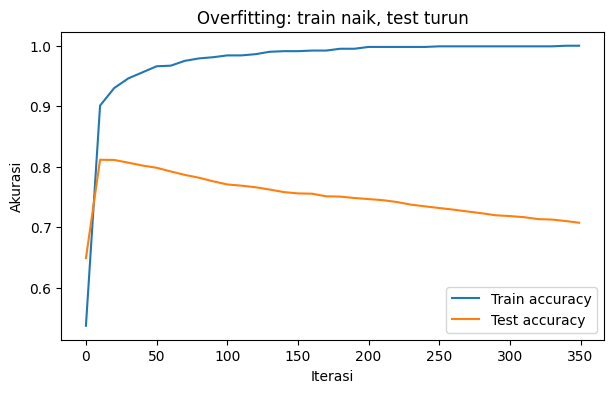

In [6]:
import matplotlib.pyplot as plt

h = np.array(hist_plain)
plt.figure(figsize=(7, 4))
plt.plot(h[:, 0], h[:, 2], label="Train accuracy")
plt.plot(h[:, 0], h[:, 4], label="Test accuracy")
plt.xlabel("Iterasi")
plt.ylabel("Akurasi")
plt.title("Overfitting: train naik, test turun")
plt.legend()
plt.show()

## 4. Overfitting pada Neural Network

Network bisa menjadi **lebih buruk** kalau dilatih terlalu lama. Analogi dari buku: cetakan garpu dari tanah liat.

Bayangkan membuat cetakan untuk mengenali apakah sebuah peralatan makan itu garpu. Kalau benda pas masuk cetakan, berarti garpu. Kita mulai dengan tanah liat basah dan seember garpu tiga mata, sendok, dan pisau. Kita tekan garpu-garpu ke tanah liat di tempat yang sama, berulang ratusan kali. Setelah kering, tidak ada sendok atau pisau yang pas, tetapi semua garpu pas. Berhasil.

Lalu seseorang memberikan garpu **empat** mata. Cetakannya punya bentuk khusus untuk tiga mata ramping, jadi garpu empat mata tidak pas, padahal itu tetap garpu. Alasannya: tanah liat tidak pernah dicetak dengan garpu empat mata. Cetakan itu overfit pada jenis garpu yang ia "latih".

Persis itu yang terjadi pada network. Weight bisa dilihat sebagai bentuk berdimensi tinggi yang mencetak diri mengikuti bentuk data selama training. Sayangnya, gambar-gambar di data uji sedikit berbeda dari pola di data latih, sehingga banyak yang gagal.

Definisi lebih resmi: network yang overfit adalah network yang mempelajari **noise** pada dataset, alih-alih mengambil keputusan hanya berdasarkan **sinyal** yang sebenarnya.

## 5. Dari Mana Overfitting Datang

Ubah skenarionya. Bayangkan tanah liat segar lagi, tetapi kali ini hanya satu garpu yang ditekan. Kalau tanahnya tebal, cetakannya tidak punya banyak detail, hanya bentuk garpu yang umum dan kabur. Bentuk itu mungkin cocok untuk garpu tiga maupun empat mata.

Jadi cetakan makin buruk pada data uji seiring semakin banyak garpu yang ditekan, karena ia mempelajari detail data latih yang makin halus. Akibatnya ia menolak gambar yang sedikit saja berbeda dari yang berulang kali dilihat. Pada analogi garpu, detail itu adalah jumlah mata garpu. Pada gambar, detail itu disebut **noise**.

Semua yang membuat sebuah gambar unik di luar inti makna "anjing", itu noise. Pada foto anjing di bantal, bantal dan latar belakang adalah noise. Pada gambar anjing hitam, bagian tengah yang gelap juga bentuk noise, karena yang menunjukkan itu anjing sebenarnya adalah tepi-tepinya.

Bagaimana membuat network melatih dirinya hanya pada sinyal dan mengabaikan noise? Salah satu caranya: **early stopping**.

## 6. Regularisasi Paling Sederhana: Early Stopping

Hentikan training ketika network mulai memburuk. Bagaimana membuat network mengabaikan detail halus dan hanya menangkap informasi umum (bentuk umum anjing atau digit MNIST)? Jangan biarkan ia dilatih cukup lama untuk mempelajari detail itu. Pada cetakan garpu, butuh banyak garpu ditekan berkali-kali untuk menghasilkan garis luar sempurna garpu tiga mata. Beberapa tekanan pertama hanya menangkap bentuk dangkalnya. Network sama saja. Early stopping adalah bentuk regularisasi paling murah, dan kalau terdesak, bisa cukup efektif.

> **Regularisasi**: himpunan metode untuk mendorong generalisasi pada model, sering dengan membuat model lebih sulit mempelajari detail halus pada data latih. Ia membantu network mempelajari sinyal dan mengabaikan noise.

Lalu bagaimana tahu kapan berhenti? Satu-satunya cara: menjalankan model pada data yang tidak ada di data latih. Biasanya dipakai dataset kedua yang disebut **validation set**. Kalau data test dipakai untuk menentukan kapan berhenti, kita justru bisa overfit ke data test. Aturan umum: jangan pakai test set untuk mengendalikan training, pakai validation set.

In [7]:
# Contoh sederhana early stopping: ambil iterasi dengan test accuracy tertinggi
# (di praktik, gunakan VALIDATION set terpisah, bukan test set)
best = max(hist_plain, key=lambda r: r[4])
print(f"Iterasi terbaik: {best[0]}  Test-Acc: {best[4]:.4f}")
print(f"Iterasi terakhir: {hist_plain[-1][0]}  Test-Acc: {hist_plain[-1][4]:.4f}")

Iterasi terbaik: 10  Test-Acc: 0.8114
Iterasi terakhir: 349  Test-Acc: 0.7073


## 7. Regularisasi Standar Industri: Dropout

Metodenya: matikan neuron secara acak (set jadi 0) selama training. Biasanya delta pada node yang sama juga ikut dimatikan selama backpropagation (secara teknis tidak wajib). Akibatnya network berlatih hanya memakai bagian acak dari dirinya.

Teknik ini umumnya diterima sebagai regularisasi andalan yang mutakhir untuk sebagian besar network. Caranya sederhana dan murah, walaupun intuisi mengapa ia berhasil lebih rumit.

> **Mengapa dropout bekerja (versi disederhanakan)**: dropout membuat network besar berperilaku seperti network kecil dengan melatih bagian-bagian kecilnya secara acak, dan network kecil tidak overfit.

Semakin kecil sebuah network, semakin kecil kemampuannya untuk overfit. Network kecil tidak punya banyak daya ekspresif, sehingga tidak bisa menangkap detail granular (noise) yang menjadi sumber overfitting. Ia hanya punya ruang untuk fitur besar yang jelas. Bayangkan tanah liat yang tersusun dari kerikil sebesar koin: mustahil mencetak garpu dengan detail, karena tiap kerikil terdorong oleh bagian besar garpu dan hanya merata-ratakan bentuknya. Sebaliknya, tanah liat dari pasir halus punya jutaan butir kecil yang masuk ke setiap sudut, dan itu yang memberi network besar daya ekspresif untuk overfit.

Bagaimana mendapatkan kekuatan network besar dengan ketahanan network kecil terhadap overfitting? Ambil network besar dan matikan node secara acak. Ketika memakai sebagian kecil network besar, ia berperilaku seperti network kecil. Dan karena dilakukan secara acak pada jutaan subnetwork yang berbeda, total network tetap mempertahankan daya ekspresifnya.

## 8. Mengapa Dropout Bekerja: Ensembling Bekerja

Dropout adalah bentuk melatih banyak network lalu merata-ratakannya. Network selalu dimulai secara acak. Setiap network belajar sedikit berbeda, dan dua network tidak pernah sama persis kecuali dimulai dengan kondisi yang sama. Saat dua network overfit, tidak ada dua network yang overfit dengan cara yang sama. Overfitting berhenti begitu semua gambar latih terprediksi sempurna (error = 0), padahal tiap network memulai dari tebakan acak dan membuat kesalahan berbeda sehingga pembaruannya berbeda.

Konsep intinya:

> Walau network besar tanpa regularisasi besar kemungkinan overfit pada noise, kecil kemungkinan mereka overfit pada **noise yang sama**.

Dan konsep penyeimbangnya:

> Walau dibuat acak, network tetap mulai dengan mempelajari fitur terbesar dan paling umum sebelum mempelajari noise.

Kesimpulannya: kalau kita melatih 100 network acak, mereka cenderung menempel pada noise yang berbeda tetapi sinyal umum yang mirip. Jadi ketika membuat kesalahan, kesalahan mereka sering berbeda. Kalau mereka diizinkan memilih secara setara, noise-nya cenderung saling meniadakan, menyisakan hanya apa yang dipelajari bersama: sinyal.

## 9. Dropout dalam Kode

Menambahkan dropout ke hidden layer (50% node dimatikan secara acak selama training) hanya perlu perubahan tiga baris. Potongan intinya:

```python
dropout_mask = np.random.randint(2, size=layer_1.shape)
layer_1 *= dropout_mask * 2
...
layer_1_delta *= dropout_mask
```

Penjelasan:

- `dropout_mask` adalah matriks acak berisi 1 dan 0 (distribusi Bernoulli 50%): tiap nilai bernilai 1 dengan peluang 50%, dan 0 dengan peluang 50%. Mengalikan `layer_1` dengan mask ini mematikan node secara acak.
- Mengapa dikali **2**? `layer_2` melakukan weighted sum atas `layer_1`. Kalau separuh node mati, jumlahnya turun separuh, sehingga `layer_2` jadi lebih "sensitif" terhadap `layer_1` (seperti orang mendekat ke radio yang volumenya kecil). Namun saat uji, dropout tidak dipakai dan volume kembali normal, jadi `layer_2` salah mendengar. Kita menyeimbangkan dengan mengalikan `layer_1` dengan `1 / (persentase node aktif)`, yaitu 1/0,5 = 2. Dengan begitu "volume" `layer_1` sama antara training dan testing.
- `layer_1_delta *= dropout_mask` memastikan node yang dimatikan juga tidak ikut menerima pembaruan.

Berikut network lengkap dengan dropout. Hidden layer diperbesar menjadi 100 node dan iterasi 300.

In [8]:
def train_with_dropout(alpha=0.005, iterations=300, hidden_size=100, eval_every=10, seed=1):
    np.random.seed(seed)
    w01 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    w12 = 0.2 * np.random.random((hidden_size, 10)) - 0.1
    history = []

    for j in range(iterations):
        error, correct_cnt = 0.0, 0
        for i in range(len(images)):
            l0 = images[i:i+1]
            l1 = relu(np.dot(l0, w01))

            dropout_mask = np.random.randint(2, size=l1.shape)
            l1 *= dropout_mask * 2

            l2 = np.dot(l1, w12)
            error += np.sum((labels[i:i+1] - l2) ** 2)
            correct_cnt += int(np.argmax(l2) == np.argmax(labels[i:i+1]))

            d2 = labels[i:i+1] - l2
            d1 = d2.dot(w12.T) * relu2deriv(l1)
            d1 *= dropout_mask

            w12 += alpha * l1.T.dot(d2)
            w01 += alpha * l0.T.dot(d1)

        if j % eval_every == 0 or j == iterations - 1:
            te, ta = evaluate(w01, w12)
            history.append((j, error / len(images), correct_cnt / len(images), te, ta))
            print(f"I:{j} Test-Err:{te:.3f} Test-Acc:{ta:.4f} "
                  f"Train-Err:{error/len(images):.3f} Train-Acc:{correct_cnt/len(images):.3f}")
    return w01, w12, history


w01_do, w12_do, hist_dropout = train_with_dropout()

I:0 Test-Err:0.641 Test-Acc:0.6333 Train-Err:0.891 Train-Acc:0.413
I:10 Test-Err:0.459 Test-Acc:0.7870 Train-Err:0.472 Train-Acc:0.764
I:20 Test-Err:0.416 Test-Acc:0.8133 Train-Err:0.431 Train-Acc:0.809
I:30 Test-Err:0.421 Test-Acc:0.8114 Train-Err:0.416 Train-Acc:0.811
I:40 Test-Err:0.420 Test-Acc:0.8112 Train-Err:0.413 Train-Acc:0.827
I:50 Test-Err:0.410 Test-Acc:0.8133 Train-Err:0.392 Train-Acc:0.836
I:60 Test-Err:0.413 Test-Acc:0.8236 Train-Err:0.402 Train-Acc:0.836
I:70 Test-Err:0.412 Test-Acc:0.8033 Train-Err:0.383 Train-Acc:0.857
I:80 Test-Err:0.411 Test-Acc:0.8054 Train-Err:0.387 Train-Acc:0.854
I:90 Test-Err:0.411 Test-Acc:0.8144 Train-Err:0.377 Train-Acc:0.868
I:100 Test-Err:0.411 Test-Acc:0.7903 Train-Err:0.370 Train-Acc:0.864
I:110 Test-Err:0.411 Test-Acc:0.8003 Train-Err:0.372 Train-Acc:0.868
I:120 Test-Err:0.403 Test-Acc:0.8046 Train-Err:0.353 Train-Acc:0.857
I:130 Test-Err:0.409 Test-Acc:0.8091 Train-Err:0.352 Train-Acc:0.867
I:140 Test-Err:0.406 Test-Acc:0.8083 Train-Er

## 10. Dropout Dievaluasi pada MNIST

Tanpa dropout, network di buku mencapai test accuracy **81,14%** sebelum turun hingga **70,73%** di akhir training. Dengan dropout, test accuracy puncaknya **82,36%** dan akhir training **81,81%**, jadi tidak overfit separah itu. Dropout juga memperlambat naiknya akurasi training, yang sebelumnya langsung 100% dan bertahan di sana.

Ini menunjukkan apa itu dropout sebenarnya: **noise**. Ia membuat network lebih sulit berlatih pada data latih. Seperti berlari maraton dengan pemberat di kaki: latihan lebih berat, tetapi saat pemberat dilepas untuk lomba sebenarnya, kita berlari lebih cepat karena berlatih untuk sesuatu yang lebih sulit.

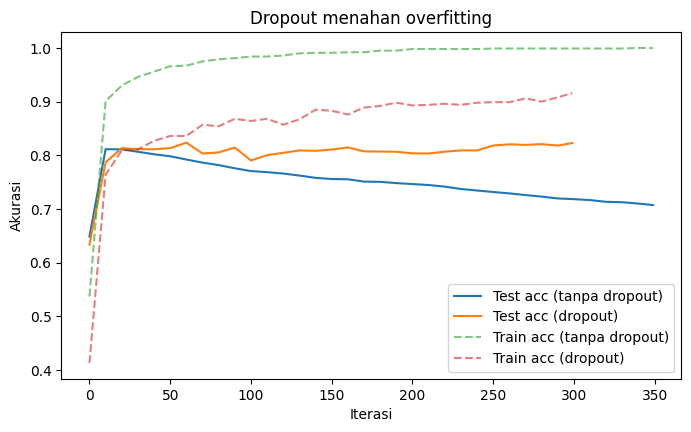

In [9]:
h0 = np.array(hist_plain)
h1 = np.array(hist_dropout)

plt.figure(figsize=(8, 4.5))
plt.plot(h0[:, 0], h0[:, 4], label="Test acc (tanpa dropout)")
plt.plot(h1[:, 0], h1[:, 4], label="Test acc (dropout)")
plt.plot(h0[:, 0], h0[:, 2], "--", label="Train acc (tanpa dropout)", alpha=0.6)
plt.plot(h1[:, 0], h1[:, 2], "--", label="Train acc (dropout)", alpha=0.6)
plt.xlabel("Iterasi")
plt.ylabel("Akurasi")
plt.title("Dropout menahan overfitting")
plt.legend()
plt.show()

## 11. Batch Gradient Descent

Metode kedua di bab ini mempercepat training dan konvergensi, yaitu **mini-batch stochastic gradient descent**. Sebelumnya kita melatih satu contoh sekali, memperbarui weight setelah tiap contoh. Sekarang kita latih 100 contoh sekaligus dan merata-ratakan pembaruan weight dari semua 100 contoh itu.

Pada output di buku, akurasi training lebih mulus dibanding sebelumnya. Rata-rata pembaruan weight secara konsisten menghasilkan efek ini, karena pembaruan dari satu contoh sangat noisy; rata-rata dari banyak contoh membuat proses belajar lebih mulus.

Perubahan kode utama:

- Layer diproses per **batch** (`layer_0 = images[batch_start:batch_end]`), jadi satu `np.dot` melakukan 100 dot product sekaligus.
- Delta dibagi `batch_size` agar menjadi rata-rata.
- Dropout mask dibuat dengan ukuran batch.

In [10]:
def train_minibatch(alpha=0.001, iterations=300, hidden_size=100, batch_size=100, eval_every=10, seed=1):
    np.random.seed(seed)
    w01 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    w12 = 0.2 * np.random.random((hidden_size, 10)) - 0.1
    history = []

    for j in range(iterations):
        error, correct_cnt = 0.0, 0

        for i in range(int(len(images) / batch_size)):
            batch_start, batch_end = (i * batch_size), ((i + 1) * batch_size)

            l0 = images[batch_start:batch_end]
            l1 = relu(np.dot(l0, w01))
            dropout_mask = np.random.randint(2, size=l1.shape)
            l1 *= dropout_mask * 2
            l2 = np.dot(l1, w12)

            error += np.sum((labels[batch_start:batch_end] - l2) ** 2)
            for k in range(batch_size):
                correct_cnt += int(np.argmax(l2[k:k+1]) ==
                                   np.argmax(labels[batch_start + k:batch_start + k + 1]))

            d2 = (labels[batch_start:batch_end] - l2) / batch_size
            d1 = d2.dot(w12.T) * relu2deriv(l1)
            d1 *= dropout_mask

            w12 += alpha * l1.T.dot(d2)
            w01 += alpha * l0.T.dot(d1)

        if j % eval_every == 0 or j == iterations - 1:
            te, ta = evaluate(w01, w12)
            history.append((j, error / len(images), correct_cnt / len(images), te, ta))
            print(f"I:{j} Test-Err:{te:.3f} Test-Acc:{ta:.4f} "
                  f"Train-Err:{error/len(images):.3f} Train-Acc:{correct_cnt/len(images):.3f}")
    return w01, w12, history


w01_mb, w12_mb, hist_mb = train_minibatch()

I:0 Test-Err:1.514 Test-Acc:0.0667 Train-Err:2.080 Train-Acc:0.084
I:10 Test-Err:1.108 Test-Acc:0.1180 Train-Err:1.534 Train-Acc:0.097
I:20 Test-Err:1.021 Test-Acc:0.1621 Train-Err:1.348 Train-Acc:0.147
I:30 Test-Err:0.974 Test-Acc:0.1973 Train-Err:1.269 Train-Acc:0.147
I:40 Test-Err:0.939 Test-Acc:0.2319 Train-Err:1.226 Train-Acc:0.141
I:50 Test-Err:0.910 Test-Acc:0.2609 Train-Err:1.128 Train-Acc:0.190
I:60 Test-Err:0.885 Test-Acc:0.2943 Train-Err:1.103 Train-Acc:0.213
I:70 Test-Err:0.864 Test-Acc:0.3233 Train-Err:1.063 Train-Acc:0.221
I:80 Test-Err:0.845 Test-Acc:0.3509 Train-Err:1.028 Train-Acc:0.253
I:90 Test-Err:0.828 Test-Acc:0.3755 Train-Err:0.993 Train-Acc:0.271
I:100 Test-Err:0.814 Test-Acc:0.3953 Train-Err:0.976 Train-Acc:0.280
I:110 Test-Err:0.801 Test-Acc:0.4166 Train-Err:0.938 Train-Acc:0.312
I:120 Test-Err:0.790 Test-Acc:0.4347 Train-Err:0.923 Train-Acc:0.316
I:130 Test-Err:0.779 Test-Acc:0.4510 Train-Err:0.910 Train-Acc:0.330
I:140 Test-Err:0.770 Test-Acc:0.4686 Train-Er

Hal pertama yang akan kita rasakan: kode ini berjalan **jauh lebih cepat**. Alasannya, setiap `np.dot` sekarang melakukan 100 dot product sekaligus, dan arsitektur CPU jauh lebih cepat mengerjakan dot product yang dibatch seperti ini.

Ada hal lain: buku menyebut bahwa dengan batching, `alpha` bisa dibuat jauh lebih besar. (Angka `alpha` pada listing buku sendiri tidak persis menunjukkan kelipatan 20 kali, jadi sebaiknya kita coba sendiri beberapa nilai `alpha` pada kode di atas.) Alasannya begini. Bayangkan mencari kota dengan kompas yang goyang. Kalau kita lihat sekali lalu berlari 2 mil, kita mungkin melenceng jauh. Tetapi kalau kita ambil 100 arah lalu merata-ratakannya, berlari 2 mil kemungkinan besar membawa kita ke arah yang kurang lebih benar. Karena rata-rata sinyal yang noisy (perubahan weight rata-rata dari 100 contoh) lebih andal, ia boleh mengambil langkah lebih besar.

Ukuran batch biasanya antara 8 sampai 256. Praktiknya, peneliti sering mencoba berbagai angka sampai menemukan pasangan `batch_size`/`alpha` yang bekerja baik.

## Poin-poin Penting Bab 8

- Network yang sempurna pada data latih belum tentu bagus. Yang penting adalah **test accuracy**, akurasi pada data yang belum pernah dilihat.
- **Overfitting** terjadi saat network mempelajari **noise** dalam data latih, bukan sinyal yang sebenarnya. Network yang makin kuat (lebih banyak weight) makin mudah overfit. Pada MNIST, test accuracy naik di awal lalu turun walau train accuracy terus naik.
- **Regularisasi** adalah kumpulan metode untuk mendorong generalisasi, sering dengan mempersulit model mempelajari detail halus.
- **Early stopping** menghentikan training saat performa pada validation set mulai memburuk. Gunakan validation set, bukan test set, untuk mengendalikan training.
- **Dropout** mematikan neuron secara acak selama training (hidden layer dikali mask 0/1, lalu dikali `1/proporsi aktif` agar skala tetap). Efeknya mirip melatih dan merata-ratakan banyak network kecil (ensembling): noise yang dipelajari tiap network berbeda sehingga saling meniadakan.
- **Mini-batch gradient descent** merata-ratakan pembaruan weight dari banyak contoh sekaligus, sehingga training lebih mulus dan jauh lebih cepat, dan `alpha` bisa diperbesar. Ukuran batch umumnya 8 sampai 256.

Referensi: Trask, A. W. (2019). *Grokking Deep Learning*, Bab 8 "Learning Signal and Ignoring Noise: Introduction to Regularization and Batching". Manning Publications.